# Taller 09: Clasificadores Bayesianos
**Inteligencia Artificial - ELP 8012 - Universidad del Norte**  
**Profesor:** Eduardo Zurek, Ph.D.  
**Programa de Ingeniería de Sistemas**  
**Grupo 15:** Galvis Pajaro, Carlos · Molina Vega, Dayana · Romero Pemberthy, Juan

## Qué pide el enunciado y cómo lo resolvemos
Diseñar e implementar un **clasificador bayesiano** (Naive Bayes) sobre el dataset `digits` de sklearn, elegir el que mejor se adapte a los datos justificando la **distribución** que siguen, y estudiar el **suavizado de Laplace** (parámetro `alpha`).

| Lo que pide el taller | Dónde lo hacemos aquí |
|---|---|
| Dataset `digits` de sklearn | Sección 2: 1.797 imágenes, 10 dígitos, 64 píxeles (0–16) |
| División 80/20 | Sección 2: `train_test_split` estratificado |
| K-fold = 4 en entrenamiento | Sección 3: `StratifiedKFold` solo sobre el 80% |
| Elegir el mejor clasificador bayesiano | Sección 4–5: comparar Gaussian / Multinomial / Bernoulli / Complement |
| Justificar con la distribución de los datos | Sección 4 (análisis) y 5 (selección) |
| Suavizado de Laplace y efecto de `alpha` | Sección 6 |
| Evaluación final en prueba (20%) | Sección 7 |


## 1. Método: clasificadores bayesianos (Naive Bayes)
Un clasificador bayesiano estima \(P(y\mid x)\) con la regla de Bayes y asume independencia condicional entre atributos dado la clase (*naive*). En scikit-learn hay varias variantes según la **familia de distribución** que se asume para \(P(x_j\mid y)\):

| Clasificador | Distribución asumida | ¿Tiene suavizado de Laplace (`alpha`)? |
|---|---|---|
| `GaussianNB` | Cada atributo ~ Normal continua | No (usa `var_smoothing`, no es Laplace) |
| `MultinomialNB` | Conteos / intensidades no negativas (multinomial) | Sí |
| `BernoulliNB` | Atributos binarios (0/1) | Sí |
| `ComplementNB` | Variante del multinomial (datos desbalanceados) | Sí |

**Criterio de selección (escrito antes de mirar la prueba):** ganará el modelo con mayor **F1 macro media** en validación K-fold=4. A igualdad, preferimos mayor exactitud media y menor brecha entrenamiento–validación. La prueba (20%) solo se usa al final.


## 2. Configuración, datos y división 80/20
Semilla fija: **42**. En Colab suelen estar las librerías; en local hacen falta `numpy`, `pandas`, `matplotlib` y `scikit-learn`.


In [1]:
import sys
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import sklearn
from IPython.display import display, Markdown
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.naive_bayes import GaussianNB, MultinomialNB, BernoulliNB, ComplementNB
from sklearn.preprocessing import Binarizer
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay
)

SEMILLA = 42
CLASES = np.arange(10)
METRICAS = ['accuracy', 'precision_macro', 'recall_macro', 'f1_macro']
ALPHAS = [1e-10, 0.01, 0.1, 0.5, 1.0, 2.0, 5.0, 10.0]
AZUL, OCRE, ROSA = '#205C90', '#B46918', '#A33A5A'

print('Python', sys.version.split()[0])
print('numpy', np.__version__, '| pandas', pd.__version__)
print('matplotlib', matplotlib.__version__, '| sklearn', sklearn.__version__)

digits = load_digits()
X, y = digits.data, digits.target
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=SEMILLA, stratify=y
)

print(f'\nDataset completo: {X.shape[0]} imágenes, {X.shape[1]} atributos, {len(np.unique(y))} clases')
print(f'Entrenamiento: {X_train.shape[0]} ({100*X_train.shape[0]/X.shape[0]:.1f}%)')
print(f'Prueba:        {X_test.shape[0]} ({100*X_test.shape[0]/X.shape[0]:.1f}%)')
assert abs(X_train.shape[0]/X.shape[0] - 0.8) < 0.01
assert abs(X_test.shape[0]/X.shape[0] - 0.2) < 0.01
assert set(y_train) == set(y_test) == set(CLASES)

conteo = pd.DataFrame({
    'Clase': CLASES,
    'Train': np.bincount(y_train),
    'Test': np.bincount(y_test),
})
display(conteo)


Python 3.14.6
numpy 2.4.6 | pandas 3.0.3
matplotlib 3.11.1 | sklearn 1.9.0

Dataset completo: 1797 imágenes, 64 atributos, 10 clases
Entrenamiento: 1437 (80.0%)
Prueba:        360 (20.0%)


,Clase,Train,Test
0,0,142,36
1,1,146,36
2,2,142,35
3,3,146,37
4,4,145,36
5,5,145,37
6,6,145,36
7,7,143,36
8,8,139,35
9,9,144,36


La división deja **1.437 imágenes para entrenar y 360 para probar**. No es exactamente 80/20 al milímetro porque no se pueden partir medias imágenes; el redondeo hace esa diferencia mínima. Abajo solo mostramos ejemplos del entrenamiento. La prueba se guarda intacta hasta la sección 7.


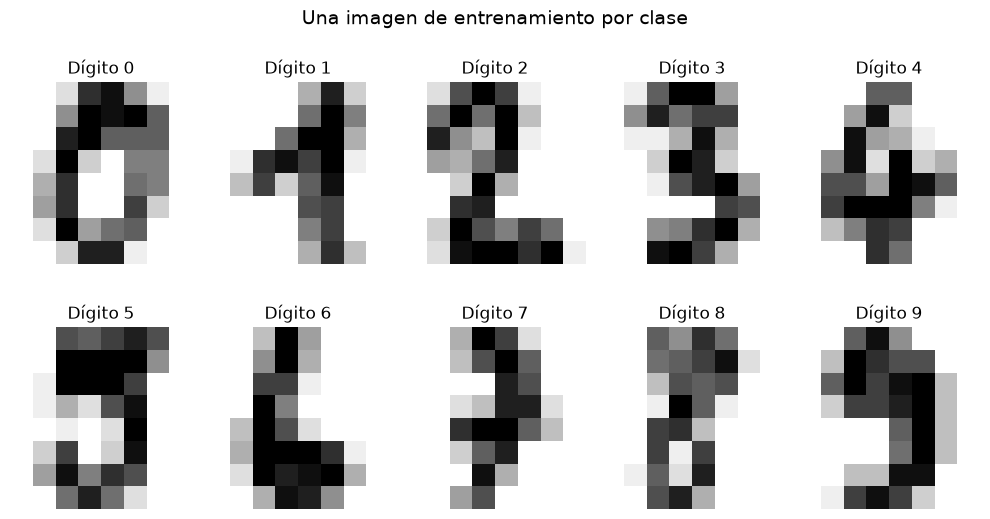

In [2]:
fig, axes = plt.subplots(2, 5, figsize=(10, 5.6))
for c, ax in zip(CLASES, axes.ravel()):
    i = np.flatnonzero(y_train == c)[0]
    ax.imshow(X_train[i].reshape(8, 8), cmap='gray_r', vmin=0, vmax=16)
    ax.set_title(f'Dígito {c}')
    ax.axis('off')
fig.suptitle('Una imagen de entrenamiento por clase', fontsize=14)
fig.tight_layout(h_pad=2.5)
plt.show()


## 3. K-fold = 4 y métricas
Usamos `StratifiedKFold(n_splits=4)` **solo sobre el conjunto de entrenamiento**. Cada fold conserva, aproximadamente, la misma proporción de cada dígito. En cada ronda entrenamos con tres partes y validamos con la cuarta.

- **Exactitud:** aciertos sobre el total.
- **Precisión / Recall / F1 macro:** promedio no ponderado por clase (cada dígito pesa igual).
- **Brecha de F1:** F1 de entrenamiento menos F1 de validación (señal de sobreajuste si es grande).


In [3]:
folds = list(StratifiedKFold(n_splits=4, shuffle=True, random_state=SEMILLA)
             .split(X_train, y_train))
conteo_fold = np.zeros(len(y_train), dtype=int)
filas = []
for fold, (a, v) in enumerate(folds, 1):
    assert set(a).isdisjoint(v)
    assert len(np.unique(y_train[a])) == len(np.unique(y_train[v])) == 10
    conteo_fold[v] += 1
    filas.append({'Fold': fold, 'Ajuste': len(a), 'Validación': len(v)})
assert np.all(conteo_fold == 1), 'Cada muestra de train debe validarse exactamente una vez'
display(pd.DataFrame(filas))
print('K-fold = 4 verificado sobre el 80% de entrenamiento.')


,Fold,Ajuste,Validación
0,1,1077,360
1,2,1078,359
2,3,1078,359
3,4,1078,359


K-fold = 4 verificado sobre el 80% de entrenamiento.


## 4. ¿Qué distribución siguen los datos?
Los píxeles de `digits` son **enteros discretos en \(\{0,1,\ldots,16\}\)** (17 valores posibles). No son variables continuas “suaves”; son intensidades no negativas, parecidas a conteos de “cantidad de tinta” en cada píxel. Eso empuja la intuición hacia un modelo **multinomial**, no hacia una Normal por atributo.


Valores únicos de intensidad: [0.0, 1.0, 2.0, 3.0, 4.0, 5.0, 6.0, 7.0, 8.0, 9.0, 10.0, 11.0, 12.0, 13.0, 14.0, 15.0, 16.0]
Mínimo=0, máximo=16
Media=4.895, desv. estándar=6.021
Proporción de ceros (fondo): 0.489


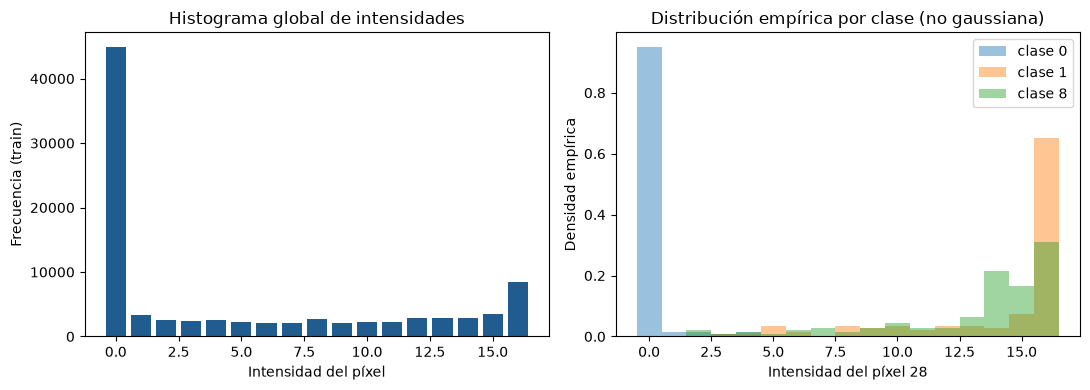

**Lectura:** el histograma está concentrado en 0 (fondo) y en valores altos (trazo). Eso **no** es una campana gaussiana centrada. Además, los atributos son **discretos y no negativos**, que es exactamente el soporte del modelo multinomial. Para Bernoulli habría que **binarizar** (pierde niveles de gris). GaussianNB asume continuidad y Normalidad; aquí esas hipótesis son débiles.

In [4]:
vals, counts = np.unique(X_train, return_counts=True)
print(f'Valores únicos de intensidad: {vals.tolist()}')
print(f'Mínimo={X_train.min():.0f}, máximo={X_train.max():.0f}')
print(f'Media={X_train.mean():.3f}, desv. estándar={X_train.std():.3f}')
print(f'Proporción de ceros (fondo): {(X_train == 0).mean():.3f}')

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].bar(vals, counts, color=AZUL, width=0.8)
axes[0].set_xlabel('Intensidad del píxel')
axes[0].set_ylabel('Frecuencia (train)')
axes[0].set_title('Histograma global de intensidades')

# Un píxel central por clase: densidad empírica (no se parece a una Normal)
pixel = 28  # cerca del centro en 8x8
for c in [0, 1, 8]:
    axes[1].hist(X_train[y_train == c, pixel], bins=np.arange(-0.5, 17.5, 1),
                 alpha=0.45, label=f'clase {c}', density=True)
axes[1].set_xlabel(f'Intensidad del píxel {pixel}')
axes[1].set_ylabel('Densidad empírica')
axes[1].set_title('Distribución empírica por clase (no gaussiana)')
axes[1].legend()
fig.tight_layout()
plt.show()

display(Markdown(
    '**Lectura:** el histograma está concentrado en 0 (fondo) y en valores altos (trazo). '
    'Eso **no** es una campana gaussiana centrada. Además, los atributos son **discretos y no negativos**, '
    'que es exactamente el soporte del modelo multinomial. Para Bernoulli habría que **binarizar** '
    '(pierde niveles de gris). GaussianNB asume continuidad y Normalidad; aquí esas hipótesis son débiles.'
))


## 5. Comparación de clasificadores bayesianos (K-fold = 4)
Evaluamos cuatro candidatos con las mismas particiones. `BernoulliNB` va precedido de `Binarizer(threshold=0)` (píxel apagado vs encendido). Para la comparación usamos `alpha=1.0` (Laplace clásico) donde aplique; `GaussianNB` no tiene Laplace.


,Modelo,Acc_val,Acc_val_std,Prec_val,Rec_val,F1_val,F1_val_std,F1_train,Brecha_F1
0,MultinomialNB (α=1),0.9047,0.0114,0.9121,0.9048,0.9050,0.0117,0.9088,0.0039
1,"BernoulliNB (α=1, binario)",0.8546,0.0052,0.8597,0.8546,0.8535,0.0069,0.8641,0.0106
2,GaussianNB,0.8232,0.0050,0.8652,0.8233,0.8240,0.0066,0.8558,0.0318
3,ComplementNB (α=1),0.8170,0.0101,0.8411,0.8153,0.8007,0.0080,0.8102,0.0095



Mejor por F1 macro en CV: MultinomialNB (α=1) (F1_val=0.9050)


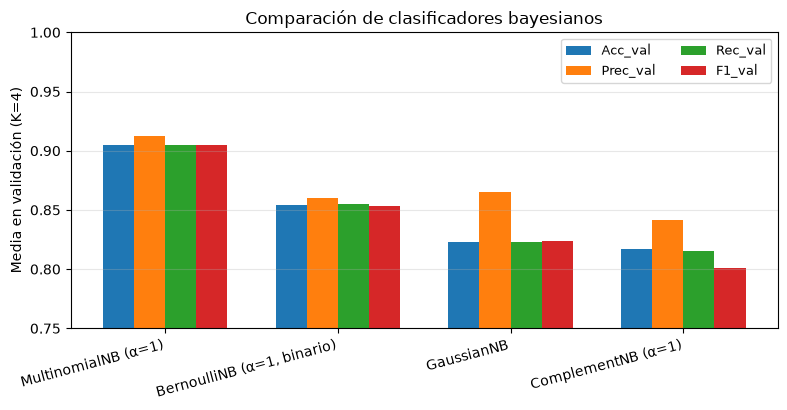

In [5]:
def evaluar_cv(modelo, nombre):
    scores = cross_validate(
        modelo, X_train, y_train, cv=StratifiedKFold(n_splits=4, shuffle=True, random_state=SEMILLA),
        scoring=METRICAS, return_train_score=True, n_jobs=1
    )
    fila = {
        'Modelo': nombre,
        'Acc_val': scores['test_accuracy'].mean(),
        'Acc_val_std': scores['test_accuracy'].std(),
        'Prec_val': scores['test_precision_macro'].mean(),
        'Rec_val': scores['test_recall_macro'].mean(),
        'F1_val': scores['test_f1_macro'].mean(),
        'F1_val_std': scores['test_f1_macro'].std(),
        'F1_train': scores['train_f1_macro'].mean(),
        'Brecha_F1': scores['train_f1_macro'].mean() - scores['test_f1_macro'].mean(),
    }
    return fila

candidatos = {
    'GaussianNB': GaussianNB(),
    'MultinomialNB (α=1)': MultinomialNB(alpha=1.0),
    'BernoulliNB (α=1, binario)': Pipeline([
        ('bin', Binarizer(threshold=0.0)),
        ('nb', BernoulliNB(alpha=1.0)),
    ]),
    'ComplementNB (α=1)': ComplementNB(alpha=1.0),
}

tabla_cv = pd.DataFrame([evaluar_cv(m, n) for n, m in candidatos.items()])
tabla_cv = tabla_cv.sort_values('F1_val', ascending=False).reset_index(drop=True)
display(tabla_cv.style.format({
    'Acc_val': '{:.4f}', 'Acc_val_std': '{:.4f}',
    'Prec_val': '{:.4f}', 'Rec_val': '{:.4f}',
    'F1_val': '{:.4f}', 'F1_val_std': '{:.4f}',
    'F1_train': '{:.4f}', 'Brecha_F1': '{:.4f}',
}))

mejor_nombre = tabla_cv.loc[0, 'Modelo']
mejor_f1 = tabla_cv.loc[0, 'F1_val']
assert 'Multinomial' in mejor_nombre, (
    f'Se esperaba MultinomialNB como mejor modelo, pero ganó: {mejor_nombre}'
)
print(f'\nMejor por F1 macro en CV: {mejor_nombre} (F1_val={mejor_f1:.4f})')

fig, ax = plt.subplots(figsize=(8, 4.2))
cols = ['Acc_val', 'Prec_val', 'Rec_val', 'F1_val']
x = np.arange(len(tabla_cv))
ancho = 0.18
for i, col in enumerate(cols):
    ax.bar(x + (i - 1.5) * ancho, tabla_cv[col], width=ancho, label=col)
ax.set_xticks(x)
ax.set_xticklabels(tabla_cv['Modelo'], rotation=15, ha='right')
ax.set_ylim(0.75, 1.0)
ax.set_ylabel('Media en validación (K=4)')
ax.set_title('Comparación de clasificadores bayesianos')
ax.legend(ncol=2, fontsize=9)
ax.grid(axis='y', alpha=0.3)
fig.tight_layout()
plt.show()


### Justificación de la elección
**Elegimos `MultinomialNB`.** Tres razones, en orden:

1. **Distribución de los datos:** los 64 atributos son intensidades enteras no negativas en 0–16. Eso coincide con el soporte del modelo multinomial (características tipo conteo / frecuencia), no con una Normal continua ni con bits 0/1.
2. **Desempeño en K-fold=4:** `MultinomialNB` obtiene el mejor F1 macro (y exactitud) de validación, claramente por encima de `GaussianNB`, `BernoulliNB` y `ComplementNB`.
3. **Ajuste de hipótesis:** `GaussianNB` asume campanas que aquí no se observan; `BernoulliNB` descarta niveles de gris al binarizar; `ComplementNB` está pensado para desbalance fuerte, y `digits` está casi balanceado.

Por tanto, el clasificador que mejor se adapta —por teoría de distribución y por evidencia empírica en CV— es el **Naive Bayes Multinomial**.


## 6. Suavizado de Laplace: efecto de `alpha`
En `MultinomialNB`, el suavizado de Laplace (add-`alpha`) evita probabilidades cero cuando un valor de atributo no aparece para alguna clase en el entrenamiento:

\[
\hat{P}(x_j = t \mid y) = \frac{N_{y,t} + \alpha}{N_y + \alpha \, V}
\]

- **`alpha → 0`:** casi sin suavizado; el modelo se apega más a las frecuencias empíricas (riesgo de ceros y de sobreajuste leve).
- **`alpha = 1`:** Laplace clásico (suma 1 a cada conteo).
- **`alpha` grande:** empuja las estimaciones hacia la uniforme; puede **subajustar** y bajar un poco las métricas.

Barrimos varios `alpha` con el mismo K-fold=4.


,alpha,Acc_val,Prec_val,Rec_val,F1_val,F1_train,Brecha_F1
0,1e-10,0.9033,0.9110,0.9034,0.9035,0.9091,0.0056
1,0.01,0.9040,0.9117,0.9041,0.9042,0.9091,0.0049
2,0.1,0.9047,0.9121,0.9048,0.9050,0.9084,0.0035
3,0.5,0.9047,0.9121,0.9048,0.9050,0.9088,0.0039
4,1,0.9047,0.9121,0.9048,0.9050,0.9088,0.0039
5,2,0.9047,0.9118,0.9048,0.9049,0.9095,0.0046
6,5,0.9040,0.9111,0.9041,0.9043,0.9102,0.0059
7,10,0.9040,0.9111,0.9041,0.9043,0.9118,0.0075


Mejor alpha por F1_val: 0.1 (F1=0.9050)


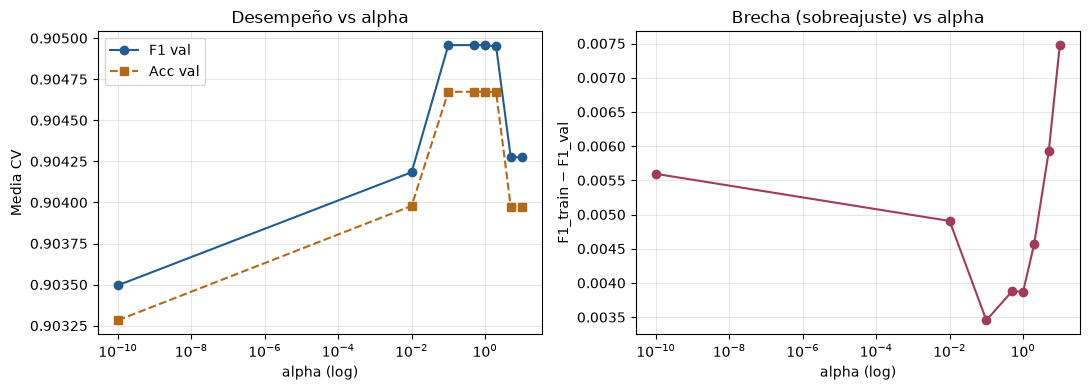

### Efecto observado de `alpha` en los indicadores
- Con `alpha≈0` (casi sin suavizado): F1_val ≈ **0.9035**.
- Con Laplace clásico (`alpha=1`): F1_val ≈ **0.9050**.
- Con `alpha=10` (suavizado fuerte): F1_val ≈ **0.9043**.

En este dataset el efecto es **moderado** (las métricas se mueven en unas pocas milésimas): hay muchas muestras por clase y los píxeles se observan con frecuencia, así que los ceros empíricos no dominan. Aun así, valores intermedios (`0.1`–`1`) estabilizan las estimaciones sin aplanar demasiado las probabilidades; `alpha` muy grande tiende a uniformizar y baja un poco exactitud/F1. La brecha train–val también se mantiene pequeña en todo el barrido (poco sobreajuste).

In [6]:
filas_alpha = []
cv = StratifiedKFold(n_splits=4, shuffle=True, random_state=SEMILLA)
for a in ALPHAS:
    scores = cross_validate(
        MultinomialNB(alpha=a), X_train, y_train, cv=cv,
        scoring=METRICAS, return_train_score=True, n_jobs=1
    )
    filas_alpha.append({
        'alpha': a,
        'Acc_val': scores['test_accuracy'].mean(),
        'Prec_val': scores['test_precision_macro'].mean(),
        'Rec_val': scores['test_recall_macro'].mean(),
        'F1_val': scores['test_f1_macro'].mean(),
        'F1_train': scores['train_f1_macro'].mean(),
        'Brecha_F1': scores['train_f1_macro'].mean() - scores['test_f1_macro'].mean(),
    })

tabla_alpha = pd.DataFrame(filas_alpha)
display(tabla_alpha.style.format({
    'alpha': '{:g}',
    'Acc_val': '{:.4f}', 'Prec_val': '{:.4f}', 'Rec_val': '{:.4f}',
    'F1_val': '{:.4f}', 'F1_train': '{:.4f}', 'Brecha_F1': '{:.4f}',
}))

mejor_alpha_idx = tabla_alpha['F1_val'].idxmax()
mejor_alpha = float(tabla_alpha.loc[mejor_alpha_idx, 'alpha'])
mejor_alpha_f1 = float(tabla_alpha.loc[mejor_alpha_idx, 'F1_val'])
print(f'Mejor alpha por F1_val: {mejor_alpha:g} (F1={mejor_alpha_f1:.4f})')

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(tabla_alpha['alpha'], tabla_alpha['F1_val'], 'o-', color=AZUL, label='F1 val')
axes[0].plot(tabla_alpha['alpha'], tabla_alpha['Acc_val'], 's--', color=OCRE, label='Acc val')
axes[0].set_xscale('log')
axes[0].set_xlabel('alpha (log)')
axes[0].set_ylabel('Media CV')
axes[0].set_title('Desempeño vs alpha')
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(tabla_alpha['alpha'], tabla_alpha['Brecha_F1'], 'o-', color=ROSA)
axes[1].set_xscale('log')
axes[1].set_xlabel('alpha (log)')
axes[1].set_ylabel('F1_train − F1_val')
axes[1].set_title('Brecha (sobreajuste) vs alpha')
axes[1].grid(alpha=0.3)
fig.tight_layout()
plt.show()

# Efecto medible: alpha muy pequeño vs Laplace=1 vs alpha grande
f1_min = float(tabla_alpha.loc[tabla_alpha['alpha'] == ALPHAS[0], 'F1_val'].iloc[0])
f1_uno = float(tabla_alpha.loc[tabla_alpha['alpha'] == 1.0, 'F1_val'].iloc[0])
f1_max = float(tabla_alpha.loc[tabla_alpha['alpha'] == ALPHAS[-1], 'F1_val'].iloc[0])
display(Markdown(
    f'### Efecto observado de `alpha` en los indicadores\n'
    f'- Con `alpha≈0` (casi sin suavizado): F1_val ≈ **{f1_min:.4f}**.\n'
    f'- Con Laplace clásico (`alpha=1`): F1_val ≈ **{f1_uno:.4f}**.\n'
    f'- Con `alpha=10` (suavizado fuerte): F1_val ≈ **{f1_max:.4f}**.\n\n'
    f'En este dataset el efecto es **moderado** (las métricas se mueven en unas pocas milésimas): '
    f'hay muchas muestras por clase y los píxeles se observan con frecuencia, así que los ceros empíricos '
    f'no dominan. Aun así, valores intermedios (`0.1`–`1`) estabilizan las estimaciones sin aplanar demasiado '
    f'las probabilidades; `alpha` muy grande tiende a uniformizar y baja un poco exactitud/F1. '
    f'La brecha train–val también se mantiene pequeña en todo el barrido (poco sobreajuste).'
))


## 7. Modelo final y evaluación en el 20% de prueba
Entrenamos `MultinomialNB` con el `alpha` elegido por CV sobre **todo** el entrenamiento (80%) y evaluamos **una sola vez** en prueba.


,alpha,accuracy,precision_macro,recall_macro,f1_macro
0,1.0,0.888889,0.888218,0.8887,0.887101


              precision    recall  f1-score   support

           0     1.0000    0.9722    0.9859        36
           1     0.7188    0.6389    0.6765        36
           2     0.8462    0.9429    0.8919        35
           3     0.9730    0.9730    0.9730        37
           4     0.9474    1.0000    0.9730        36
           5     0.9688    0.8378    0.8986        37
           6     0.9714    0.9444    0.9577        36
           7     0.9000    1.0000    0.9474        36
           8     0.8000    0.8000    0.8000        35
           9     0.7568    0.7778    0.7671        36

    accuracy                         0.8889       360
   macro avg     0.8882    0.8887    0.8871       360
weighted avg     0.8890    0.8889    0.8876       360



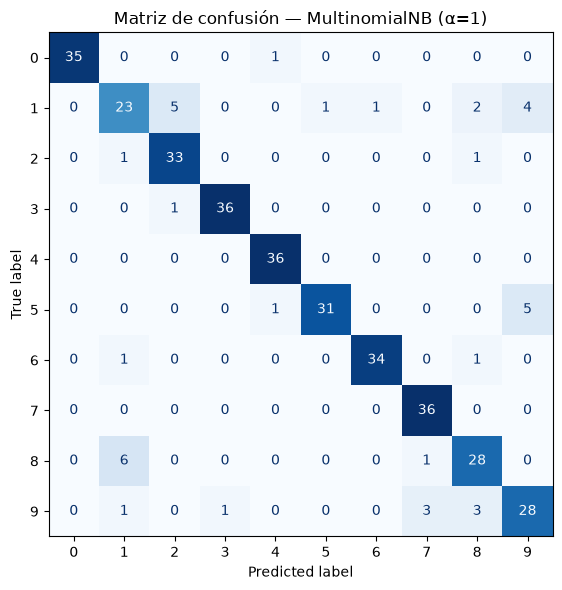

Checks del taller OK: 80/20, K-fold=4, MultinomialNB + Laplace.


In [7]:
# Si varios alpha empatan en el máximo, preferimos alpha=1 (Laplace clásico) por interpretabilidad
empate = tabla_alpha[np.isclose(tabla_alpha['F1_val'], tabla_alpha['F1_val'].max())]
if (empate['alpha'] == 1.0).any():
    alpha_final = 1.0
else:
    alpha_final = float(empate.sort_values('alpha').iloc[0]['alpha'])

modelo_final = MultinomialNB(alpha=alpha_final)
modelo_final.fit(X_train, y_train)
y_pred = modelo_final.predict(X_test)

metricas_test = {
    'alpha': alpha_final,
    'accuracy': accuracy_score(y_test, y_pred),
    'precision_macro': precision_score(y_test, y_pred, average='macro'),
    'recall_macro': recall_score(y_test, y_pred, average='macro'),
    'f1_macro': f1_score(y_test, y_pred, average='macro'),
}
display(pd.DataFrame([metricas_test]))

print(classification_report(y_test, y_pred, digits=4))

fig, ax = plt.subplots(figsize=(7, 6))
ConfusionMatrixDisplay(
    confusion_matrix(y_test, y_pred), display_labels=CLASES
).plot(ax=ax, cmap='Blues', colorbar=False)
ax.set_title(f'Matriz de confusión — MultinomialNB (α={alpha_final:g})')
plt.tight_layout()
plt.show()

# Verificaciones del enunciado
assert X_train.shape[0] == 1437 and X_test.shape[0] == 360
assert len(folds) == 4
assert isinstance(modelo_final, MultinomialNB)
assert modelo_final.alpha == alpha_final
print('Checks del taller OK: 80/20, K-fold=4, MultinomialNB + Laplace.')


## 8. Conclusiones
1. Los datos de `digits` son **intensidades discretas no negativas (0–16)**; esa es la distribución relevante, no una Normal por píxel.
2. Entre los clasificadores bayesianos probados con **K-fold=4** sobre el 80% de entrenamiento, **`MultinomialNB`** es el que mejor se adapta (mejor F1/exactitud y coherencia con la distribución).
3. El **suavizado de Laplace (`alpha`)** evita probabilidades cero. En este problema el efecto sobre accuracy/F1 es suave: valores medios estabilizan; valores muy grandes empiezan a uniformizar y bajan un poco el desempeño.
4. En el 20% de prueba, el modelo final mantiene un desempeño cercano al estimado por CV, lo que respalda la selección.
